# Gene Regulatory Dynamics
## Learning Objectives: 
## 1) Understand Gene Regulation 
#### Learn how cells control gene expression through transcription and translation, ensuring that not all genes are active at the same time.

## 2) Use Differential Equations To Model Biological Systems
#### Use differential equations to represent the production and degradation of mRNA and proteins, forming the basis for simulating gene expression

## 3) Simulate Biological Dynamics Through Numerical Integration
#### Implement numerical integration techniques in Python to more generally learn how to use code to work with dynamics systems. For this lab, we will more specifically simulate gene regulatory networks and observe how mRNA and protein levels change over time.

## 4) Analyze Fixed Points, Feedback Loops, and Stability 
#### Explore how feedback loops can play significant roles in dynamic biological systems. We will explore how feedback loops specifically affect gene expression, understand equilibrium points, and study bistability, a key concept in genetic switches and decision-making in cells.


### This lab is about simulating how living systems change over time. It focuses on gene regulation, which controls how cells turn specific genes on or off.

### The process involves DNA being transcribed into mRNA, which is then translated into proteins, and both mRNA and proteins eventually degrade.

### To simplify, the lab models this using just two components: mRNA (m) and proteins (p), with feedback mechanisms influencing their production and degradation.

<img src="Transcription.png" />


### The goal is to create mathematical equations to represent these changes and use them for simulations. The concentration of molecules is measured in nanomoles (nM), based on the volume of a single E. coli cell. The lab assumes a steady production of mRNA and proteins, following basic biological principles.

## Governing equations
### $$ dm/dt = \overbrace{a}^{\text{transcription}} - \overbrace{b_mm}^{\text{degradation}}$$
### $$ dp/dt = \overbrace{rm}^{\text{translation}} - \overbrace{b_pp}^{\text{degradation}}$$
### where a is the rate of mRNA transcription and r is the rate of translation per transcript. The concentration of mRNA and proteions are reduced by dilution at a rate b, which simulates degradation

### Differential equations can be either linear or nonlinear, and while these equations are linear - the following process can be used for either/or. To solve these equations, we use numerical simulations that break time into small steps and update values incrementally. 
## How is this done?:
### 1) First, the instantaneous rate of change for each variable (dm/dt and dp/dt) is calculated
### 2) Then a small time step ($\Delta$t) is used to estimate how much mRNA and protein levels incrementally change($\Delta$m and $\Delta$p) 
### 3) Update the new values of state variables m(t) and p(t) based on this incremental change (initially m(0) and p(0) - which we set) and repeat steps 1-2

<img src="Euler.png" />

#### Note: Python/r/matlab use a more powerful method but the basic logic is consistent. Do not attempt to actually discretely updating using Euler's method as it is super numerically unstable!
### This process, known as numerical integration, calculates changes in mRNA and protein levels at each step based on their rates of production and degradation. By running these simulations, we can predict gene expression dynamics and analyze how different conditions affect cellular behavior.

###  In Python, we can solve coupled Ordinary Differential Equations (ODEs) using the scipy.integrate.odeint function

## Setting Up the Simulation
### We start by defining a function to solve the ODEs:


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

#t = np.linspace(t0, tf)  # Time points
#x = integrate.odeint(odefun, x0, t, args=(pars,))

# t represents time points.
# x is the solution to the ODE.
# odefun is the function defining the system of equations.
# t0 and tf are the initial and final time.
# x0 is the initial condition.
# pars holds the parameters.

#Note: The x variable can store multiple variables, such as mRNA concentration and protein concentration over time.

## Defining the Protein Production Model
### The function below models how mRNA (m) and protein (p) change over time:

In [10]:

def proteinproduction(x, t, pars):
    m = x[0]
    p = x[1]
    
    dmdt = pars['a'] - pars['bm']*m
    dpdt = pars['r']*m - pars['bp']*p
    
    dxdt = np.array([dmdt, dpdt])
    return dxdt
    
# m = x[0] and p = x[1] extract mRNA and protein values.
# The equations describe mRNA production & decay (dmdt) and protein production & decay (dpdt).
# The output dxdt is a vector containing both rates of change.

In [11]:
# Parameters
pars = {} #Define a dictionary of parameters we are going to use 
pars['a'] = 10 # nM/hr
pars['bm'] = 2 # 1/hr
pars['bp'] = 1 # 1/hr 
pars['r'] = 30 # proteins/(mRNA/hr) 

# Initial conditions 
x0 = [0.0, 0.0]  # Initial values [m(0),p(0)]
t0 = 0.0         # Start time
tf = 21.0        # Finish time 
t = np.linspace(t0, tf, 100)

# Simulate
x = integrate.odeint(proteinproduction, x0, t, args=(pars,))

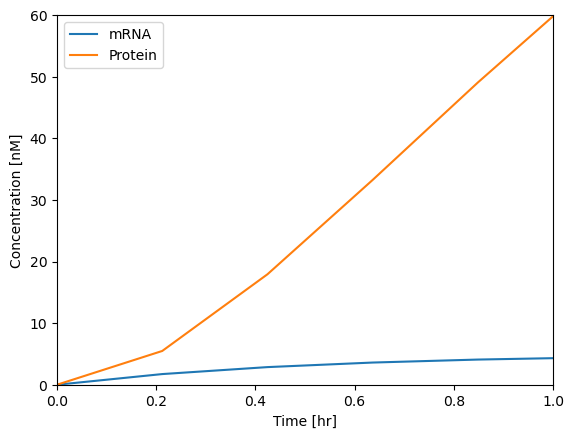

In [12]:
plt.plot(t, x, label=["mRNA", "Protein"])
plt.legend()
plt.xlabel("Time [hr]")
plt.ylabel("Concentration [nM]");
plt.xlim(0, 1.0); plt.ylim(0, 60.0);

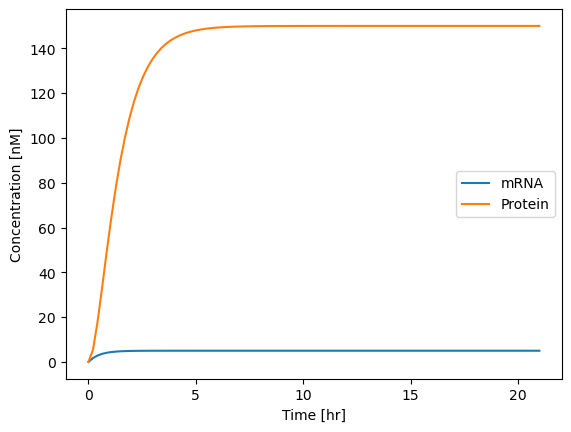

In [13]:
plt.plot(t, x, label=["mRNA", "Protein"])
plt.legend()
plt.xlabel("Time [hr]")
plt.ylabel("Concentration [nM]");


<div class="alert alert-block alert-warning">
<b>Challenge Problem: Organizing variables</b> 
    
***

This challenge has two parts:
1. Add a new field termed `aRange` to the dictionary pars with values from 10 to
50 with a step size of 2. 
2. Create a new dictionary called stats with three matrices as fields, `tvals`, `mvals`,
and `pvals`, each with the number of columns as the length of `aRange` and 100 rows. Initialize all entries to 0.
Notably, this format can be used to collect results from many simulations in a single variable.
</div>

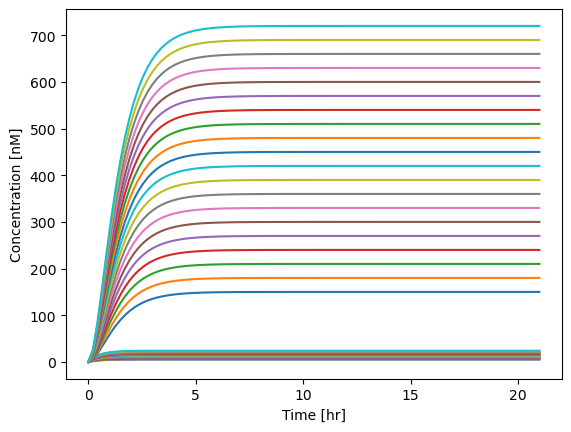

In [15]:
# Challenge 1: add a new field termed aRange with values from 5 to 50 with a step size of 2.
pars={} #initiate parameter dictionary
pars['a']=10 #nM/hr
pars['bm']=2 # /hr
pars['bp']=1 #/hr
pars['r']=30#proteins/(mRNA*hr)
# New field-value
pars['aRange'] = np.arange(10,50,2)
# Challenge 2: create a new structure called stats with three matrices as fields, tvals, mvals, and pvals, each with
#the number of columns as the length of arange and 100 rows. Initialize all entries to 0.
stats = {}
stats['tvals'] = np.zeros((100,len(pars['aRange'])) )
stats['pvals'] = np.zeros((100,len(pars['aRange'])) )
stats['mvals'] = np.zeros((100,len(pars['aRange'])) )

for i in np.arange(len(pars['aRange'])):
    pars['a'] = pars['aRange'][i]
    x = integrate.odeint(proteinproduction, x0, t, args=(pars,))
    stats['tvals'][:,i] = t 
    stats['pvals'][:,i] = x[:,0]
    stats['mvals'][:,i] = x[:,1]

plt.plot(stats['tvals'], stats['pvals']);
plt.plot(stats['tvals'], stats['mvals']);
plt.xlabel("Time [hr]")
plt.ylabel("Concentration [nM]");


## Understanding Fixed Points and Phase Space in Dynamic Systems

### In the previous simulations, the system stabilized at mRNA concentration m(t) --> 5nm and protein concentration p(t) --> 150 nM. 
### This was expected because the system reached a fixed point, meaning the concentrations no longer change over time.

### A fixed point occurs when the rate of change is zero: 
#### $$dm/dt = 0, dp/dt = 0$$ 

### By analytically doing the math and solving for equilibrium values, we get that the fixed points are : 
### $$ m^* = 5nM,  p^* = 150nM $$ 
### This tells us that once the system reaches these values, it will remain there indefinitely.

## What Happens When the System is Not at a Fixed Point?
### When the system is away from the fixed point, the variables continue to change over time. 
### To understand this behavior, we need to analyze transient dynamics—the process of approaching equilibrium.
### Biologists often study time-series plots, where each variable is plotted against time. 
### However, an alternative approach is to analyze how each variable changes with respect to the others --> Phase Diagrams


![SegmentLocal](Harmonic.gif "segment")

### Our task : instead of plotting m(t) and p(t) separately against time, we can plot m vs. p directly. 
### This representation is called phase space, where time is implicit rather than explicitly shown.

### For this system, phase space is a 2D plane defined by  (m,p). 
### In more complex systems with more variables, the phase space can have higher dimensions.

### By analyzing the system in phase space, we can observe:


#### 1) How the system moves toward equilibrium.
#### 2) Whether the system oscillates or converges directly.
#### 3) How different initial conditions affect the trajectory.

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Visualizing Phase Space Dynamics</b> 
    
***

Write code that visualizes phase-space dynamics of a mRNA-protein system over a 24 hr period with parameters as above, given 4 different sets of initial conditions $(m(0), p(0)) = {(0, 0),(20, 5),(2, 200),(10, 50)}$. The
resulting dynamics should look as shown in this box, where open circles denote the initial conditions, the gray
curve denote trajectories, and the black closed circle denotes the expected fixed point:

**Hint**: use the command plt.plot to plot the two output components against one another, corresponding to
m(t) and p(t), respectively. In addition, using an array of initial conditions can help with your overlay.
</div>

Text(0, 0.5, 'Protein, p(t) [nM]')

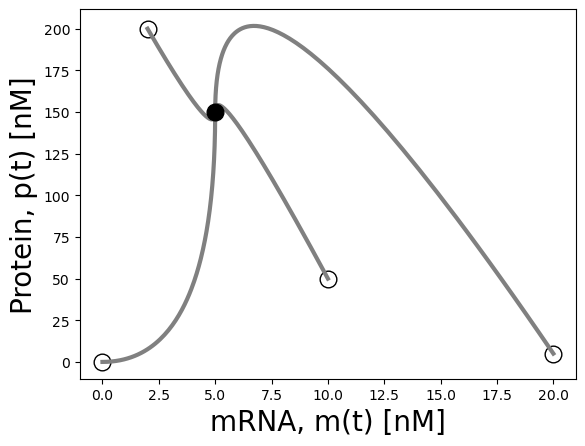

In [21]:
pars={} #initiate parameter dictionary
pars['a']=10 #nM/hr
pars['bm']=2 # /hr
pars['bp']=1 #/hr
pars['r']=30#proteins/(mRNA*hr)
# Initial conditions
#Array of initial values
x0_range=[[0,0],
          [20,5],
          [2,200],
          [10,50]]

t = np.linspace(t0, tf, 1000)
# Simulate/visualize
for i in range(len(x0_range)):
    x0 = x0_range[i]
    plt.plot(x0[0],x0[1], marker='o', markersize=12, markeredgecolor='k', markerfacecolor='w')
    x = integrate.odeint(proteinproduction, x0, t, args=(pars,))
    plt.plot(x[:,0],x[:,1],color=[0.5,0.5,0.5],linewidth=3)
    
#Visualize the expected fixed point
plt.plot(pars['a']/pars['bm'], pars['r']*pars['a']/(pars['bm']*pars['bp']), 
         marker='o', markersize=12, color='k')
#Label
plt.xlabel('mRNA, m(t) [nM]',fontsize=20)
plt.ylabel('Protein, p(t) [nM]',fontsize=20)

## Understanding Nullclines in Dynamic Systems
### To analyze how a system behaves away from equilibrium, we use nullclines. 
### A nullcline is a set of points in phase space where the rate of change of a variable is zero. For the mRNA-protein system, there are two nullclines:

### - The mRNA nullcline, where $dm/dt = 0$
### - The protein nullcline, where $dp/dt = 0$

### Solving these two differential equations gives us $m^* = \frac{a}{b_m}$ and $p^* = \frac{rm}{b_p}$
### Biologically, this means that the concentration of mRNA and protein remain constant at $m^* = \frac{a}{b_m}$ and $p^* = \frac{rm}{b_p}$ respectively

### When plotted, the intersection of the nullclines gives the fixed point $(m^*,p^*)$


## Why Are Nullclines Important?
### Nullclines help us: 
#### - Find equilibria, where both variables stop changing.
#### - Understand variable interactions, since crossing a nullcline changes the direction of change.
#### - Predict system behavior, especially when far from equilibrium.
### Key finding: When plotted, the intersection of the nullclines gives the fixed point $(m^*,p^*)$, which is the equilibrium of the entire system

Text(0, 0.5, 'Protein Concentration (nMol)')

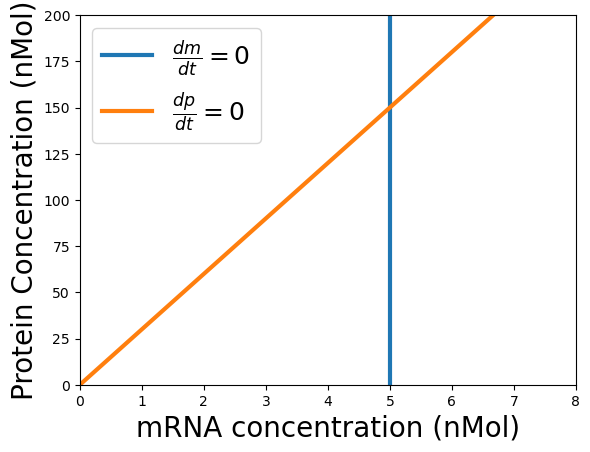

In [24]:
# Define the nullclines
mnullcline = pars['a']/pars['bm'] # A fixed value
pnullcline = lambda p : pars['bp']/pars['r'] * p # An ’anonymous’ function
# Define a vector of protein and mRNA values
pvec = np.arange(0,201,20)
mvec = np.arange(0,9)
# Plot the nullclines
plt.plot(mnullcline*np.ones(np.shape(pvec)), pvec, linewidth=3) 
#plt.axhline(mnullcline)
plt.plot(pnullcline(pvec), pvec, linewidth=3)
# Label the plot
plt.legend([r'$\frac{dm}{dt} = 0$',r'$\frac{dp}{dt} = 0$'],fontsize=18)
plt.xlim(min(mvec),max(mvec))
plt.ylim(min(pvec),max(pvec))
plt.xlabel('mRNA concentration (nMol)',fontsize=20)
plt.ylabel('Protein Concentration (nMol)',fontsize=20)
#plt.scatter(pars['a']/pars['bm'], pars['r']*pars['a']/(pars['bp']*pars['bm']), color='k', s=100)

### Nullclines don’t show movement, but a velocity field does. This helps us see the local direction and magnitude of flow
### This velocity field can be used to help interpret anticipated dynamics and even stability as examined in the next challenge problem.

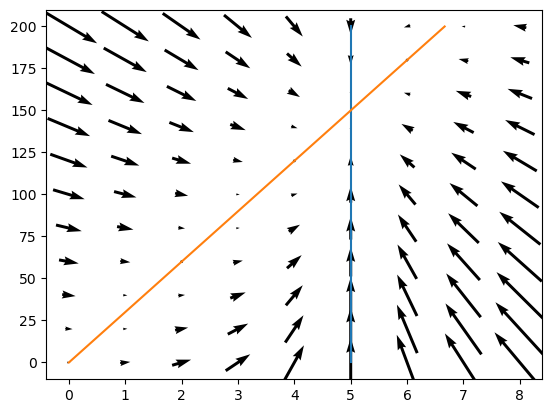

In [26]:
# Define rate of change
dmdt = lambda pars,m: pars['a']-pars['bm']*m
dpdt = lambda pars,m,p : pars['r']*m-pars['bp']*p
[MM,PP] = np.meshgrid(mvec,pvec)
# Replot the nullclines
plt.plot(mnullcline*np.ones(np.shape(pvec)),pvec)
plt.plot(pnullcline(pvec),pvec)
# Overlay the arrows
plt.quiver(MM,PP,dmdt(pars,MM),dpdt(pars,MM,PP),pivot='mid', angles='xy')

### This quiver plot:

#### - Uses arrows to show how mRNA and protein change at different points.
####  - Shows how the system moves toward equilibrium.
#### - Helps interpret stability and dynamic

<div class="alert alert-block alert-warning">
<b>Connecting Dynamics to Nullclines</b> 
    
***
The dynamics depend on the starting conditions. For both (0, 0) and (7, 25), the system converges to the equilibrium
at (5, 150). For (1, 150), first proteins decrease and then recover as new mRNA is produced. The realized dynamics are
shown are shown below, where the code assumes that you are adding these dynamics on top of the prior visualization
commands using lighter arrows to highlight the vector fields and dashed lines to plot the nullclines
</div>

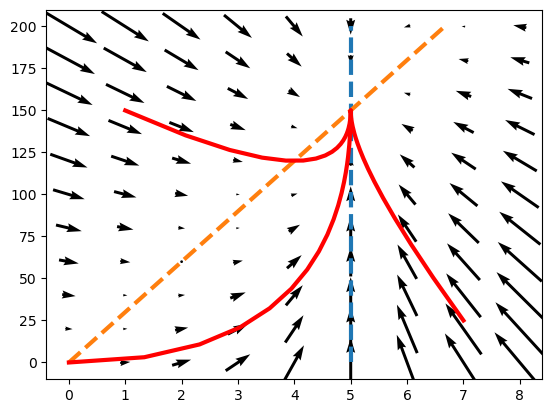

In [29]:
#Don’t forget to replot the nullclines and quivers
plt.plot(mnullcline*np.ones(np.shape(pvec)),pvec, linewidth=3, linestyle='dashed')
plt.plot(pnullcline(pvec), pvec, linewidth=3, linestyle='dashed')
plt.quiver(MM,PP,dmdt(pars,MM),dpdt(pars,MM,PP),pivot='mid', angles='xy')

m0_vec = [0, 1, 7]
p0_vec = [0, 150, 25]
t0=0
tf=31.0
t=np.linspace(t0,tf,200)
for i in range(3):
    x0=[m0_vec[i], p0_vec[i]]
    x = integrate.odeint(proteinproduction,x0,t,args=(pars,))
    plt.plot(x[:,0],x[:,1],linewidth=3,color='r')


#### By starting from different initial values of  m and  p, we can see whether the system always settles at equilibrium or exhibits different behaviors. 
#### The dynamics depend on the starting conditions.

#### For both (0, 0) and (7, 25), the system converges to the equilibrium at (5, 150). 

#### For (1, 150), first proteins decrease and then recover as new mRNA is produced.

#### The realized dynamics are shown above, where the code assumes that you are adding these dynamics on top of the prior visualization-
#### commands using lighter arrows to highlight the vector fields and dashed lines to plot the nullclines

## Evaluating Stability of Equilibrium
### What is Stability?
#### - A system is stable if, after a small disturbance, it returns to its equilibrium state.
#### - It is unstable if a small disturbance causes it to move further away from equilibrium.
### The key question: Will the system always return to equilibrium, or can it settle into different states?

### Finding Equilibria
#### Equilibrium happens when dm/dt = 0 and dp/dt = 0, which we did above using the nullclines to find the equilibrium point at ($m^*$, $p^*$) 
#### This tells us nothing about the stability of the system when disturbed from its equilibrium though...

### Linear Stability Analysis
#### To check stability, we linearize the system using a mathematical tool called the Jacobian matrix
#### In a system of two differential equations, like our mRNA-protein model $$ dm/dt = f(m,p) $$ and $$ dp/dt = g(m,p) $$ 
### The Jacobian matrix is the of partial derivatives 
### $J = \begin{bmatrix}\partial f / \partial m &\partial f / \partial p \\ \partial g / \partial m &\partial g / \partial p \end{bmatrix}$
### Each element in the matrix describes how one variable changes in response to another. 
### The point of the Jacobian is tell us how each variable influences the other.

### Plugging in the partial derivatives for our system gives us the Jacobian:
### $J = \begin{bmatrix}-b_m &0\\ r &-b_p \end{bmatrix}$

<span style="color: Blue;">
    
### But what do the Jacobian elements mean? More specifically, what does each element tell us about the system?

### Each element of the Jacobian tells us something about the system:

#### (Example): Top left ($-b_m$): $\partial f / \partial m$ --> How mRNA affects itself. Since the only way it effects itself is through degradation, this is negative with a magnitude $b_m$.
</span>

#### - Top left ($-b_m$): $\partial f / \partial m$ --> How mRNA affects itself. Since the only way it effects itself is through degradation, this is negative.
#### - Top right ($0$): $\partial f / \partial p$ --> How protein affects mRNA. Remember, there is no direct effect of protein on mRNA in our model and therefire this is 0.
#### - Bottom left ($r$): $\partial g / \partial m$ --> How mRNA affects protein. Since mRNA produces protein, this is positive r.
#### - Bottom right ($-b_p$): $\partial g / \partial p$ --> How protein affects itself. Since the only way it effects itself is through degradation, this is negative with a magnitude $b_p$.

#### Note: Although the entries in this particular matrix are all fixed parameters, for nonlinearsystem these entries will also depend on the state variables. 
#### In that case, the Jacobian must be evaluated at the fixed point of relevance, i.e., substituting the values of each variable with its corresponding value.


### Stability Analysis Using the Jacobian 
#### The stability of equilibrium is determined by the eigenvalues of the Jacobian matrix.
#### Eigenvalues ($\lambda$) are found by solving: $$ det(J-\lambda I) = 0 $$ where I is the identity matrix $I = \begin{bmatrix}1 &0\\ 0 &1\end{bmatrix}$
#### $$ J-λI = \begin{bmatrix}-b_m -\lambda  &0\\ r &-b_p -\lambda \end{bmatrix} $$
#### $$ det(J-λI) = (-b_m -\lambda)(-b_p -\lambda) - (0 \times r) $$
#### $$ \lambda^2 + (b_m +b_p) \lambda + (b_m b_p) = 0 $$

### Interpreting the Eigenvalues
#### - If both eigenvalues are negative, the equilibrium is stable (system returns to equilibrium after disturbance)
#### - If any eigenvalue is positive, the equilibrium is unstable (system moves away from equilibrium)
#### - If an eigenvalue is zero, the system is at a critical point (bifurcation may occur)

<span style="color: Blue;">
    
#### Question for you all: What is going on with our eigenvalues? Can you tell me if the system is stable and explain why using the final characeristic equation above?

</span>

### Since $b_m, b_p > 0$, it is easy to see that both our eigenvalues have to be negative and therefore the equilibrium is stable!

##  Numerically Evaluating Stability of Equilibria
### Why Simulate Near Equilibria?
### We previously calculated stability mathematically using the Jacobian matrix
### But sometimes doing the math above for complicated systems can be quite difficult
### Now, we simulate what happens when the system is slightly perturbed from equilibrium
### The goal is to observe whether the system returns to equilibrium or moves away 

<span style="color: Blue;">
    
## Run code under section B : Numerical simulations near equilibria

</span>

Text(0, 0.5, 'Protein Concentration (nMol)')

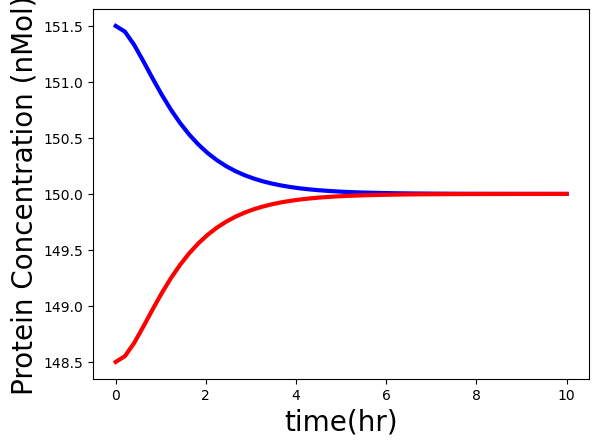

In [36]:
# Find fixed points: We first calculate the equilibrium concentrations for mRNA and protein
pstar=pars['r']*pars['a']/pars['bm']/pars['bp']
mstar=pars['a']/pars['bm']

# Perturb initial conditions: We slightly increase or decrease the values at the fixed points
# This represents a small disturbance in the system.
pperturb=pstar*0.01
mperturb = mstar*0.01

x_plus=[mstar+mperturb,pstar+pperturb]
x_minus=[mstar-mperturb,pstar-pperturb]

t0=0
tf=10
t=np.linspace(t0,tf)


# Simulate and visualize just the proteins --> if the system returns back to m*,p* it is stable 
# However if the system moves away from fixed points it is unstable

x=integrate.odeint(proteinproduction,x_plus,t,args=(pars,))
plt.plot(t,x[:,1],linewidth=3,color='b')

x=integrate.odeint(proteinproduction,x_minus,t,args=(pars,))
plt.plot(t,x[:,1],linewidth=3,color='r')

plt.xlabel('time(hr)',fontsize=20)
plt.ylabel('Protein Concentration (nMol)',fontsize=20)

### Both mRNA and protein levels settle back to their steady-state values --> stable 

### But... what happens when parameters change?
### Sometimes, a system has multiple equilibria, leading to bistability.


## Simulating bistability in one dimension

### What is Bistability?
#### - Bistability means a system has two stable equilibrium states
#### - Depending on initial conditions, the system can settle into either state
#### - This is essential for biological systems like genetic switches, where a cell can "remember" a past state

### To show bistability, we will use a simple positive feedback loop 
### In this loop, protein enhances its own production 
### $$ \frac{dx}{dt} = \frac{\beta x^n}{K^n + x^n} - \alpha x$$

### Where x is the density of proteins, $\beta$ is the maximal production rate, K is the half-saturation constant, $\alpha$ is the decay rate, and $n$ is the  term that defines the degree of cooperativity for positive feedback (Hill coefficient)

### Limit behavior: 
### - When x is high (x>>K), the first term essentially simplifies as $K^n + x^n \simeq x^n$ --> $\frac{\beta x^n}{K^n + x^n} \simeq \frac{\beta x^n}{x^n} \simeq \beta$
### This leads to $\frac{dx}{dt} \simeq \beta - \alpha x$, which has an $x^* = \beta / \alpha$
### --> For large x production dominates initially, but as x increases, degradation catches up and balances production at steady state.

<span style="color: Blue;">
    
### Question: What happens when x is low (x<<K), tell me the behavior at the limit and the eventual $x^*$
</span>


### - When x is low (x<<K), there is very little going on in the first term 
### $\frac{\beta x^n}{K^n + x^n} \simeq \frac{x^n}{K^n}$, which is very small for small x 
### Therefore degradation term $\alpha x$ dominates and $\frac{dx}{dt} \simeq - \alpha x$, which has an $x^* = 0$
### ---> For small x, the protein degrades faster than it is produced , aka the system stays 'OFF' at x = 0 

<div class="alert alert-block alert-warning">
<b>Simulating a bistable feedback loop</b> 
    
***
Write your own script to simulate a positive feedback loop and demonstrate that different initial conditions
lead to different outcomes. Use the following parameters: β = 100 nM/hr, K = 50 nM, n = 4, α = 1. If your
code works, it should lead to a result like in the book
</div>

In [41]:
def positivefeedback(x,t,pars):
    dxdt = pars['beta']*x**pars['n']/(pars['K']**pars['n'] + x**pars['n'])-pars['alpha']*x
    return(dxdt)

Text(0.5, 1.0, 'Dynamics when $\\beta$= 100 nM/hr')

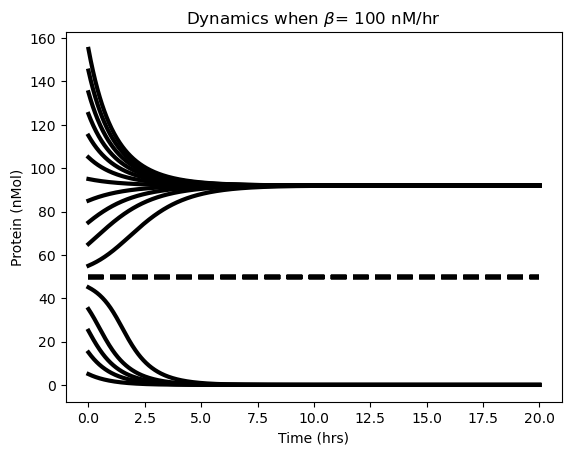

In [42]:
# Parameters
pars={} #initiate parameter dictionary
pars['beta']=100
pars['K']=50
pars['n']=4
pars['alpha']=1
#Set time limits
t0=0
tf=20
t = np.linspace(t0,tf, 1000)
#Simulate
x0range = np.arange(5,165,10)
for i in range(len(x0range)):
    x0 = x0range[i]
    x = integrate.odeint(positivefeedback,x0,t,args=(pars,))
    plt.plot(t,x,color='k',linewidth=3)
    # Visualize the split point
    plt.plot([t0,tf],[pars['K'],pars['K']],color='k',linestyle='--',linewidth=3)
plt.xlabel('Time (hrs)')
plt.ylabel('Protein (nMol)')
plt.title(r"Dynamics when $\beta$= 100 nM/hr")

## Visualizing state diagrams - towards bifurcation diagrams

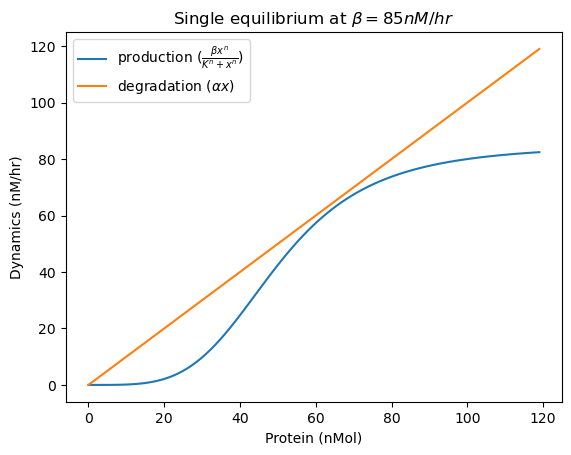

In [44]:
def production(x, pars):
    return pars['beta']*x**pars['n']/(pars['K']**pars['n'] + x**pars['n'])

def degradation(x, pars):
    return pars['alpha']*x

pars={} #initiate parameter dictionary
pars['beta']=85
pars['K']=50
pars['n']=4
pars['alpha']=1
x = np.arange(0, 120)
plt.plot(x, production(x, pars), label = r'production $(\frac{\beta x^n}{K^n + x^n})$')
plt.plot(x, degradation(x, pars), label = r'degradation $(\alpha x)$')
plt.legend()
plt.ylabel('Dynamics (nM/hr)')
plt.xlabel('Protein (nMol)')
plt.title(r'Single equilibrium at $\beta = 85 nM/hr$')
plt.show()


## State Diagram
### - X-axis (Input Protein, nMol): Represents the protein concentration in the system. This is the variable whose dynamics we are studying
### - Y-axis (Output Dynamics, nM/hr): Represents the rates of protein production (blue curve) and degradation (orange line)
### - Intersection Points: The points where the production and degradation curves meet represent the equilibria of the system (recall $ \frac{dx}{dt} = \frac{\beta x^n}{K^n + x^n} - \alpha x$)

### In this example, the only intersection/fixed point is at $x^* = 0$

<span style="color: Blue;">
    
### Question: We can see that throughout the protein x domain, degradation dominates production --> what does this mean? 
### Relate your answer back to the singular fixed point at $x^* = 0$

</span>

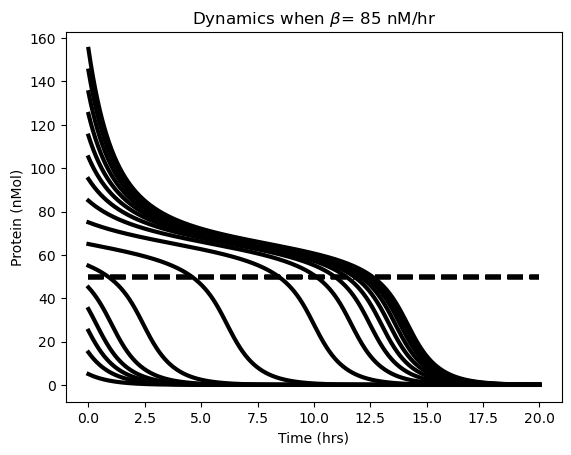

In [46]:
t0=0
tf=20
t = np.linspace(t0,tf, 1000)
#Simulate
x0range = np.arange(5,165,10)
for i in range(len(x0range)):
    x0 = x0range[i]
    x = integrate.odeint(positivefeedback,x0,t,args=(pars,))
    plt.plot(t,x,color='k',linewidth=3)
    # Visualize the split point
    plt.plot([t0,tf],[pars['K'],pars['K']],color='k',linestyle='--',linewidth=3)
plt.xlabel('Time (hrs)')
plt.ylabel('Protein (nMol)')
plt.title(r"Dynamics when $\beta$= 85 nM/hr")
plt.show()

### When $\beta = 85$, Degradation is always greater than production, so the only stable state is OFF ($x^* = 0$) 

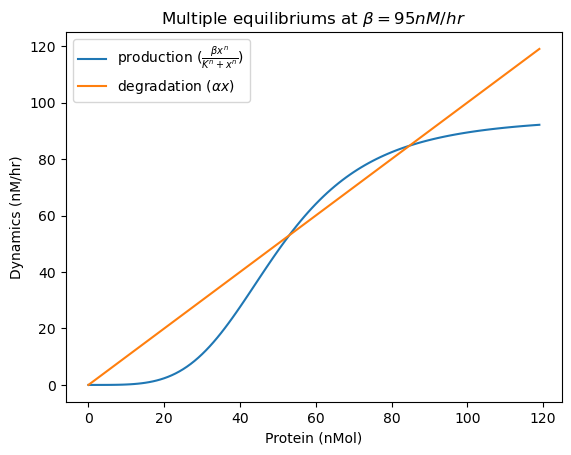

In [48]:
# Parameters
pars={} #initiate parameter dictionary
pars['beta']=95
pars['K']=50
pars['n']=4
pars['alpha']=1
x = np.arange(0, 120)
plt.plot(x, production(x, pars), label = r'production $(\frac{\beta x^n}{K^n + x^n})$')
plt.plot(x, degradation(x, pars), label = r'degradation $(\alpha x)$')
plt.legend()
plt.title(r'Multiple equilibriums at $\beta = 95 nM/hr$')
plt.ylabel('Dynamics (nM/hr)')
plt.xlabel('Protein (nMol)')
plt.show()


## When $\beta = 95$ (only a 11.7% increase in the production rate $\beta$) , the system has three fixed points —two stable states (ON and OFF) and one unstable state in between
## Stability at these fixed points can be figured out using the Jacobian analysis from earlier!
## Or... we can think about this intuitively 
## First (lowest) fixed point: 
### - If protein concentration increases slightly, degradation becomes higher than production → system returns to 0 (OFF) --> Stable!

## Third (Highest) fixed point: 
### - If protein concentration increases slightly, degradation dominates → system returns to equilibrium
### - If protein concentration decreases slightly, production dominates → system returns to equilibrium --> Stable!


<span style="color: Blue;">
    
## - What happens at the middle fixed point? Use the same process as I used above
</span>

## Middle fixed point: 
### - If protein concentration increases slightly, production becomes higher than degradation → protein levels keep increasing toward the ON state.
### - If protein concentration decreases slightly, degradation dominates → protein levels keep decreasing toward the OFF state.
## This is an unstable fixed point because small disturbances push the system away from the intersection!

Text(0.5, 1.0, 'Dynamics when $\\beta$= 95 nM/hr')

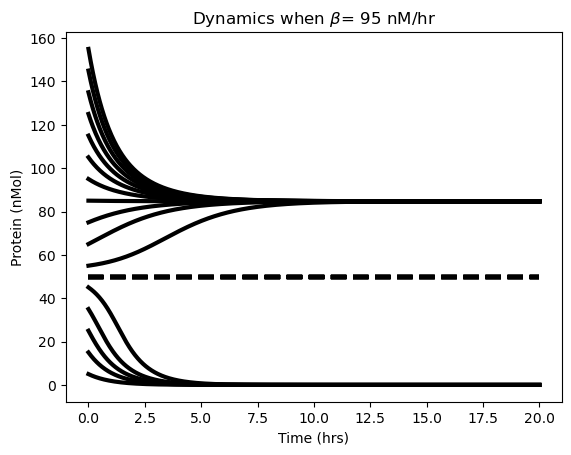

In [52]:
t0=0
tf=20
t = np.linspace(t0,tf, 1000)
#Simulate
x0range = np.arange(5,165,10)
for i in range(len(x0range)):
    x0 = x0range[i]
    x = integrate.odeint(positivefeedback,x0,t,args=(pars,))
    plt.plot(t,x,color='k',linewidth=3)
    # Visualize the split point
    plt.plot([t0,tf],[pars['K'],pars['K']],color='k',linestyle='--',linewidth=3)
plt.xlabel('Time (hrs)')
plt.ylabel('Protein (nMol)')
plt.title(r"Dynamics when $\beta$= 95 nM/hr")